# Supplementary Figure 1 — per-region SNV & indel spectra + VAF

For the seven cross-platform concordance regions (three platform-private sets, three pairwise overlaps and the all-three core), per region: the mutational profile (SNV 96-context / indel COSMIC ID-83) and the tumour VAF distribution per member platform. Restricted to the VAF ≥ 10% inclusion gate.

To reproduce, set the run folders in the Configuration cell and run all cells.

## 1 · Configuration

In [1]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
# Each platform points at a run folder (local path or gs:// URI); cell-line
# tumour samples are auto-discovered under it (section 3).
# ============================================================================
PLATFORMS = OrderedDict([
    ("Illumina", {"folder": "gs://jvt-testing/runs/hcc-il",  "color": "#E08214"}),
    ("Roche",    {"folder": "gs://jvt-testing/runs/hcc-sbx", "color": "#2C6FBB"}),
    ("Ultima",   {"folder": "gs://jvt-testing/runs/hcc-ult", "color": "#3A3A3A"}),
])
EXPECTED_CELL_LINES = ["COLO829", "HCC1187", "HCC1395", "HCC1954", "HG008"]
# ============================================================================

VAF_MIN   = 0.10     # inclusion gate: keep a variant if tumour FORMAT AF >= this on >=1 platform
CACHE_DIR = Path("data") / "molecular"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
print("Platforms:", {k: v["folder"] for k, v in PLATFORMS.items()})

Platforms: {'Illumina': 'gs://jvt-testing/runs/hcc-il', 'Roche': 'gs://jvt-testing/runs/hcc-sbx', 'Ultima': 'gs://jvt-testing/runs/hcc-ult'}


## 2 · Plotting style

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette (matches Figure 2 panel B)
SBS_CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}

def fmt(n):
    n = float(n)
    return f"{n/1000:.1f}k" if n >= 1000 else f"{n:.0f}"

## 3 · Load per-variant data (SNV 96-context + indel ID-83)

In [3]:
import subprocess, re, gzip
import numpy as np
import pandas as pd

def _ls(path):
    if str(path).startswith("gs://"):
        r = subprocess.run(["gsutil", "ls", str(path)], capture_output=True, text=True)
        return [l for l in r.stdout.splitlines() if l.strip()]
    p = Path(path)
    return [str(c) + ("/" if c.is_dir() else "") for c in p.iterdir()] if p.exists() else []

def _fetch(src, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        return dest
    if str(src).startswith("gs://"):
        subprocess.run(["gsutil", "cp", str(src), str(dest)], check=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    else:
        import shutil; shutil.copy(Path(src), dest)
    return dest

def discover_cell_lines(folder):
    folder = str(folder).rstrip("/")
    found = []
    for entry in _ls(folder + "/"):
        if not entry.endswith("/"):
            continue
        cl = entry.rstrip("/").split("/")[-1]
        base = f"{folder}/{cl}/output/{cl}"
        subdirs = [e.rstrip("/").split("/")[-1] for e in _ls(base + "/alignments/") if e.endswith("/")]
        tumor = next((s for s in subdirs if s.endswith("T")), None)
        if tumor:
            found.append((cl, tumor, base))
    return found

def _tumor_vaf(fmt, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt.split(":")
    if "AF" not in keys:
        return np.nan
    v = sample.split(":")[keys.index("AF")]
    try:
        return float(v)
    except ValueError:
        return np.nan

print("io helpers ready")

io helpers ready


In [4]:
# ---- Per-variant data for the seven Venn-region profiles (VAF + mutation channel) --------------
# Re-read the cached PURPLE somatic VCFs to retain, per PASS SNV and per PASS indel:
#   key -> (tumour VAF, mutation channel)
# SNV channel = 96-context (INFO 'TNC', pyrimidine-normalised, matches panel B).
# Indel channel = COSMIC ID-83, derived from REF/ALT + SAGE repeat (REP_C/REP_S) and microhomology
# (RC_MH) annotations (no reference genome needed). Additive: DATA and panels A-D are untouched.
from scipy.stats import gaussian_kde

_COMP = {"A": "T", "T": "A", "C": "G", "G": "C", "N": "N"}
def _rc(s):
    return "".join(_COMP[b] for b in reversed(s))

# ---- SNV: 96 trinucleotide contexts ----
def sbs96_bucket(ref, alt, tnc):
    # 'CLASS_TRI' e.g. 'C>T_ACG'; pyrimidine-normalised so ref is C or T (tnc has the ref in the middle).
    if ref in "CT":
        return f"{ref}>{alt}_{tnc}"
    return f"{_COMP[ref]}>{_COMP[alt]}_{_rc(tnc)}"

BASES = "ACGT"
BUCKETS96 = [f"{cls}_{f5}{cls[0]}{f3}" for cls in SBS_CLASSES for f5 in BASES for f3 in BASES]

# ---- Indel: COSMIC ID-83 channels (canonical order) + SigProfiler colour blocks ----
ID83_CHANNELS = (
    [f"1:Del:{b}:{i}" for b in "CT" for i in range(6)]           # 1bp deletion  (homopolymer len 1..6+)
    + [f"1:Ins:{b}:{i}" for b in "CT" for i in range(6)]         # 1bp insertion (0..5+ copies)
    + [f"{s}:Del:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]   # >1bp del at repeats
    + [f"{s}:Ins:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]   # >1bp ins at repeats
    + [f"{s}:Del:M:{j}" for s, n in ((2, 1), (3, 2), (4, 3), (5, 5)) for j in range(1, n + 1)]  # microhomology del
)
assert len(ID83_CHANNELS) == 83, len(ID83_CHANNELS)

ID83_BLOCK_COLORS = {
    "1:Del:C": "#FDBE6F", "1:Del:T": "#FF8001", "1:Ins:C": "#B0DD8B", "1:Ins:T": "#36A02E",
    "2:Del:R": "#FCC9B4", "3:Del:R": "#FC896B", "4:Del:R": "#F04432", "5:Del:R": "#BC141A",
    "2:Ins:R": "#CFE0F1", "3:Ins:R": "#93C4DE", "4:Ins:R": "#4A97C7", "5:Ins:R": "#1863AA",
    "2:Del:M": "#E1E1EE", "3:Del:M": "#B5B5D8", "4:Del:M": "#8683BD", "5:Del:M": "#61409B",
}
def id83_color(ch):
    return ID83_BLOCK_COLORS[":".join(ch.split(":")[:3])]

def _info_get(info, key, cast=str):
    m = re.search(rf"(?:^|;){key}=([^;]+)", info)
    return cast(m.group(1)) if m else None

def classify_id83(ref, alt, info):
    # Map an anchored indel (ref[0] == alt[0]) to a COSMIC ID-83 channel using SAGE annotations.
    is_del = len(ref) > len(alt)
    seq = ref[1:] if is_del else alt[1:]           # deleted / inserted bases (after the anchor base)
    size = len(seq)
    if size == 0:
        return None
    rep_c = _info_get(info, "REP_C", int) or 0
    rep_s = _info_get(info, "REP_S")
    mh = _info_get(info, "RC_MH") or ""
    if size == 1:
        base = seq if seq in "CT" else _COMP[seq]  # pyrimidine-normalise the indel base
        unit_is_base = (rep_s == seq)
        if is_del:
            hp = rep_c if (unit_is_base and rep_c >= 1) else 1     # homopolymer length in reference
            return f"1:Del:{base}:{min(hp - 1, 5)}"
        copies = rep_c if unit_is_base else 0                      # existing copies before insertion
        return f"1:Ins:{base}:{min(copies, 5)}"
    scat = min(size, 5)                                            # size class 2,3,4,5(=5+)
    is_repeat = rep_s is not None and rep_c >= 1 and size % len(rep_s) == 0
    if is_del and not is_repeat and len(mh) >= 1:                 # microhomology-mediated deletion
        cap = {2: 1, 3: 2, 4: 3, 5: 5}[scat]
        return f"{scat}:Del:M:{min(len(mh), cap)}"
    typ = "Del" if is_del else "Ins"
    return f"{scat}:{typ}:R:{min(rep_c, 5) if is_repeat else 0}"

# The seven Venn regions (A = Illumina, B = Roche, C = Ultima), matching panel D.
BIN_ORDER = [
    ("Illumina only",   ("Illumina",)),
    ("Roche only",      ("Roche",)),
    ("Ultima only",     ("Ultima",)),
    ("Illumina–Roche",  ("Illumina", "Roche")),
    ("Illumina–Ultima", ("Illumina", "Ultima")),
    ("Roche–Ultima",    ("Roche", "Ultima")),
    ("All three",       ("Illumina", "Roche", "Ultima")),
]
CHANNELS = {"snv": BUCKETS96, "indel": ID83_CHANNELS}
CH_IDX = {k: {ch: i for i, ch in enumerate(v)} for k, v in CHANNELS.items()}

def parse_variants_pervariant(path):
    # {'snv'|'indel': {(chrom,pos,ref,alt): (vaf, channel)}} for PASS variants.
    snv, indel = {}, {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            key = (c[0], c[1], ref, alt)
            vaf = _tumor_vaf(c[8], c[-1])
            if len(ref) == 1 and len(alt) == 1 and ref != alt:
                m = re.search(r"(?:^|;)TNC=([ACGTN]{3})(?:;|$)", c[7])
                if m:
                    snv[key] = (vaf, sbs96_bucket(ref, alt, m.group(1)))
            elif len(ref) != len(alt):
                ch = classify_id83(ref, alt, c[7])
                if ch:
                    indel[key] = (vaf, ch)
    return {"snv": snv, "indel": indel}

PERVAR = {}
for name in PLATFORMS:
    PERVAR[name] = {}
    for cl, tumor, base in discover_cell_lines(PLATFORMS[name]["folder"]):
        som = _fetch(f"{base}/purple/{tumor}.purple.somatic.vcf.gz",
                     CACHE_DIR / name / cl / f"{tumor}.somatic.vcf.gz")
        PERVAR[name][cl] = parse_variants_pervariant(som)
    print(f"{name}: (SNV, indel) per cell line = " +
          str({cl: (len(PERVAR[name][cl]['snv']), len(PERVAR[name][cl]['indel'])) for cl in PERVAR[name]}))

def region_bins(kind, vaf_gate=False):
    # Sum the seven Venn regions over the cell lines sequenced on all three platforms.
    # Returns (shared_cell_lines, {region: channel count vector}, {region: {platform: [VAFs]}}).
    # vaf_gate=True applies the same inclusion gate as panel D's VAF10 view: keep a variant only if
    # it reaches VAF >= VAF_MIN on at least one platform (membership stays PASS presence).
    plats = list(PLATFORMS)
    shared = sorted(set.intersection(*[set(PERVAR[p]) for p in plats]))
    idx = CH_IDX[kind]; nch = len(CHANNELS[kind])
    to_bin = {frozenset(members): label for label, members in BIN_ORDER}
    prof = {label: np.zeros(nch) for label, _ in BIN_ORDER}
    vafs = {label: {p: [] for p in plats} for label, _ in BIN_ORDER}
    for cl in shared:
        kv = {p: PERVAR[p][cl][kind] for p in plats}
        keys = {p: set(kv[p]) for p in plats}
        universe = set().union(*keys.values())
        if vaf_gate:
            universe = {k for k in universe
                        if any(k in kv[p] and not np.isnan(kv[p][k][0]) and kv[p][k][0] >= VAF_MIN
                               for p in plats)}
        for k in universe:
            members = frozenset(p for p in plats if k in keys[p])
            label = to_bin.get(members)
            if label is None:
                continue
            mp = next(p for p in plats if k in keys[p])          # channel is platform-independent
            bi = idx.get(kv[mp][k][1])
            if bi is not None:
                prof[label][bi] += 1
            for p in members:
                vafs[label][p].append(kv[p][k][0])
    return shared, prof, vafs

print("per-variant data (SNV 96-context + indel ID-83) + region_bins ready")

Illumina: (SNV, indel) per cell line = {'COLO829': (39476, 712), 'HCC1187': (12358, 1206), 'HCC1395': (43495, 2799), 'HCC1954': (22704, 2907), 'HG008': (9549, 1472)}
Roche: (SNV, indel) per cell line = {'COLO829': (39710, 642), 'HCC1187': (12719, 1426), 'HCC1395': (45333, 2751), 'HCC1954': (23014, 3274), 'HG008': (9865, 1591)}
Ultima: (SNV, indel) per cell line = {'COLO829': (40045, 586), 'HCC1187': (12336, 988), 'HCC1395': (44399, 2470), 'HCC1954': (21916, 1847), 'HG008': (9254, 1158)}
per-variant data (SNV 96-context + indel ID-83) + region_bins ready


## 4 · Per-region SNV profiles — spectrum + VAF

Wrote: figures/molecular_venn_region_profiles.pdf figures/molecular_venn_region_profiles.svg figures/molecular_venn_region_profiles.png


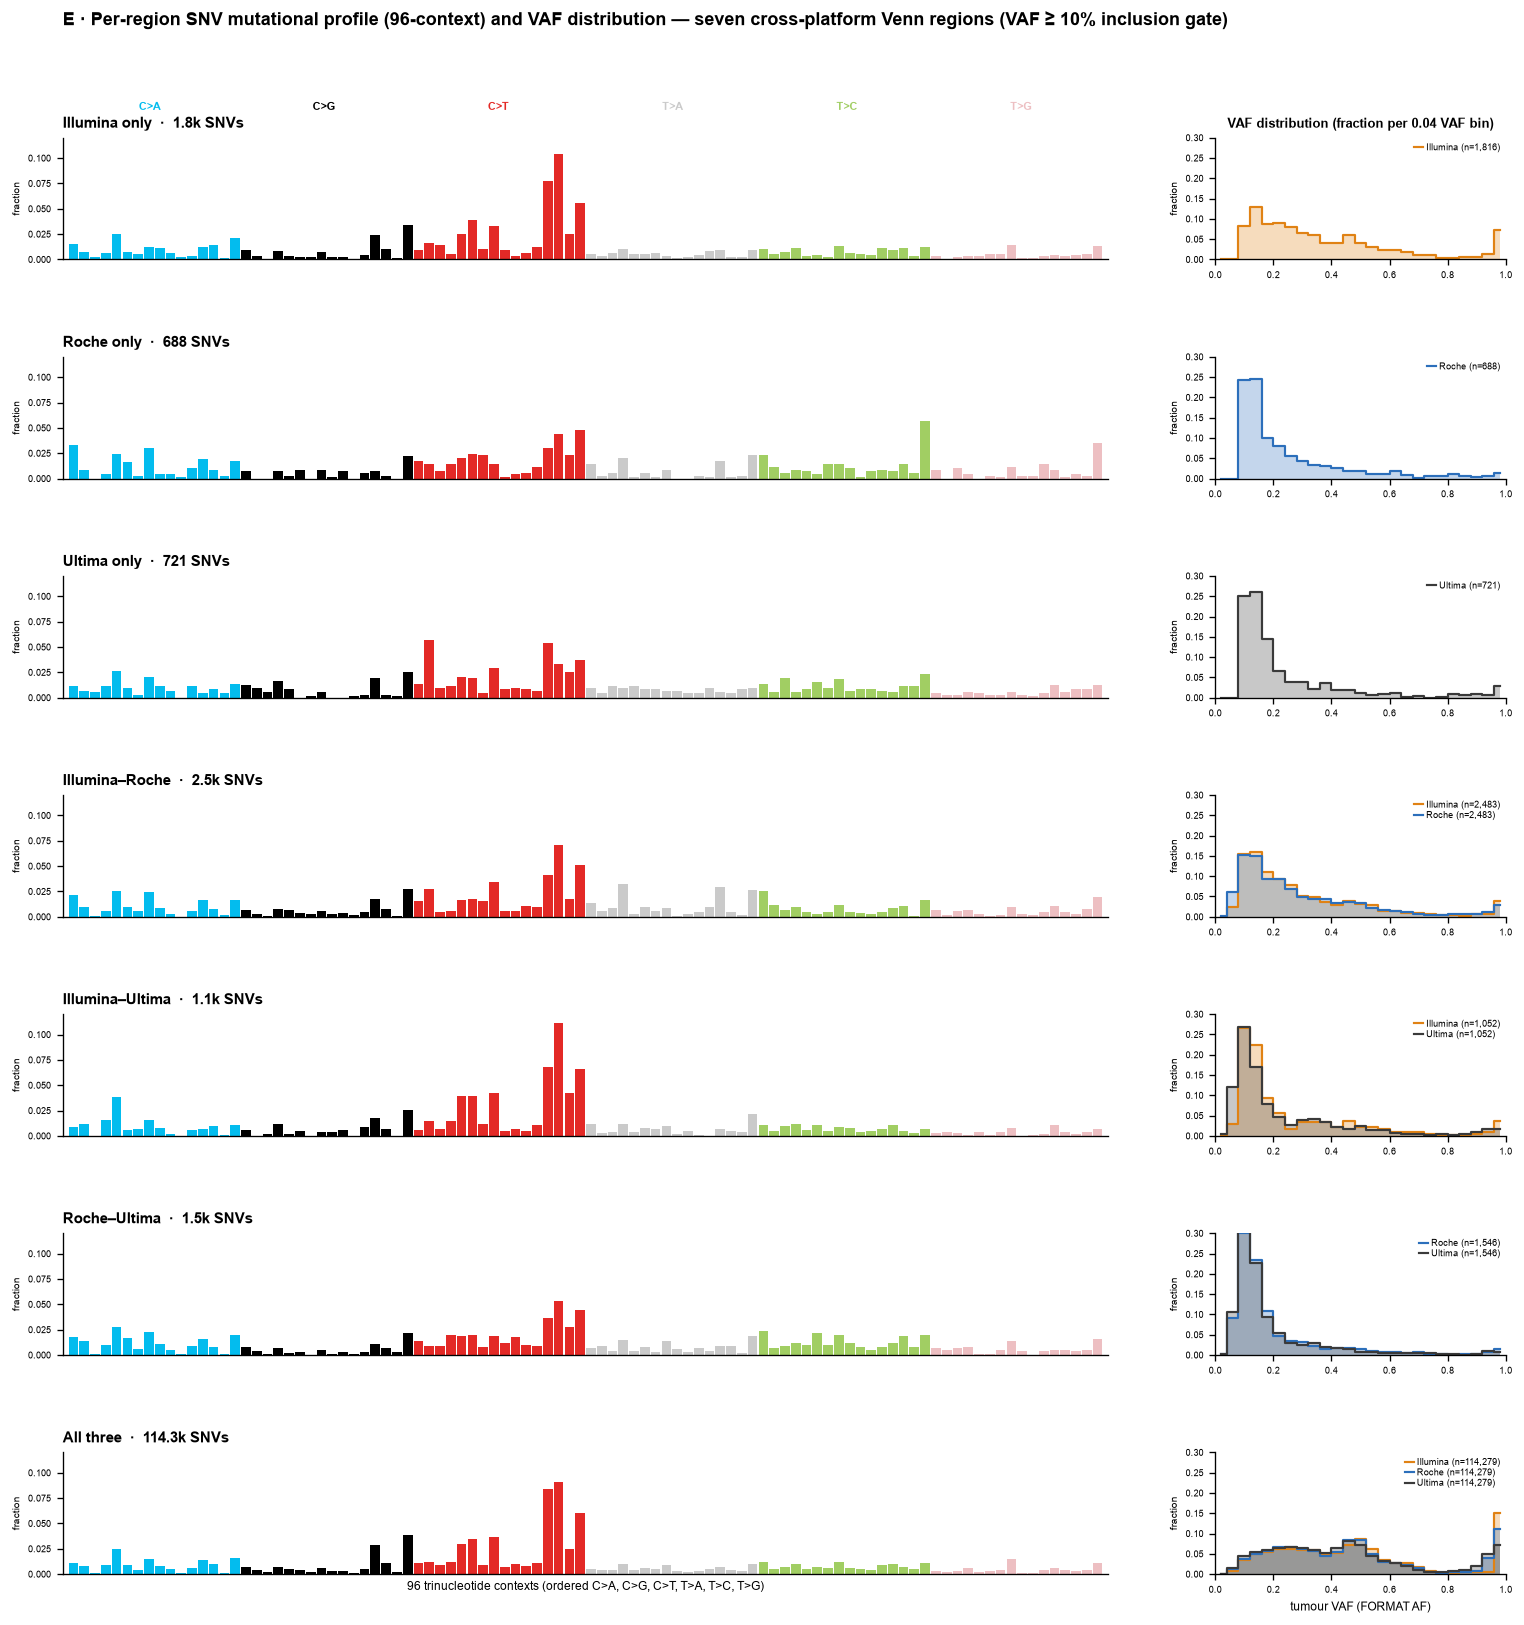

In [5]:
VAF_BINS = np.linspace(0, 1, 26)                 # 25 bins, width 0.04
_VAF_CTR = (VAF_BINS[:-1] + VAF_BINS[1:]) / 2

def _vaf_frac(values):
    # Exact histogram: fraction of the region's variants whose VAF falls in each 0.04-wide bin.
    # Bins sum to 1 -> same quantity as the mutational-spectrum 'fraction' axis (fraction of the
    # region's variants), just binned by VAF instead of by mutation channel.
    v = np.array([x for x in values if x is not None and not np.isnan(x)])
    if v.size == 0:
        return None, 0
    counts, _ = np.histogram(v, bins=VAF_BINS)
    return counts / v.size, int(v.size)

# top-band labels sit in the gap ABOVE the row-0 region title (which is at ~y=1.0)
_BAND_Y = 1.42     # group name
_MEAN_Y = 1.30     # what the per-bar number counts
_SUB_Y = 1.21      # base (C/T) or indel size

def _snv_bands(ax):
    # 6 substitution-class labels across the top of the profile.
    for ci, cls in enumerate(SBS_CLASSES):
        ax.text((ci + 0.5) / 6, _SUB_Y, cls, transform=ax.transAxes, ha="center", va="bottom",
                fontsize=6.4, weight="bold", color=(SBS_COLORS[cls] if cls != "C>G" else "#000"))

def _id83_bands(ax):
    # Three tiers over the top: group (type), what the x-number means, and the base (C/T) or size.
    n = len(ID83_CHANNELS)
    groups = [("1bp deletion", "homopolymer length", 0, 12),
              ("1bp insertion", "homopolymer length", 12, 24),
              (">1bp deletion at repeats", "repeat-unit count", 24, 48),
              (">1bp insertion at repeats", "repeat-unit count", 48, 72),
              ("microhomology deletion", "microhomology length", 72, 83)]
    for name, meaning, a, b in groups:
        x = (a + b) / 2 / n
        ax.text(x, _BAND_Y, name, transform=ax.transAxes, ha="center", va="bottom",
                fontsize=6.2, weight="bold", color="#333")
    subs = [("C", 0, 6), ("T", 6, 12), ("C", 12, 18), ("T", 18, 24),          # base for 1bp blocks
            ("2", 24, 30), ("3", 30, 36), ("4", 36, 42), ("5+", 42, 48),       # deletion size (bp)
            ("2", 48, 54), ("3", 54, 60), ("4", 60, 66), ("5+", 66, 72),       # insertion size (bp)
            ("2", 72, 73), ("3", 73, 75), ("4", 75, 78), ("5+", 78, 83)]       # MH deletion size (bp)
    for name, a, b in subs:
        ax.text((a + b) / 2 / n, _SUB_Y, name, transform=ax.transAxes, ha="center", va="bottom",
                fontsize=5.4, color="#666")

def _id83_xticklabels():
    # Per-channel number under each bar: homopolymer length / repeat-unit count / microhomology length.
    labs = []
    for ch in ID83_CHANNELS:
        sz, typ, cat, i = ch.split(":"); i = int(i)
        if cat == "M":
            labs.append(str(i))                              # microhomology length (bp)
        elif sz == "1" and typ == "Del":
            labs.append("6+" if i == 5 else str(i + 1))      # homopolymer length 1..6+
        else:
            labs.append("5+" if i == 5 else str(i))          # repeat-unit count / inserted copies 0..5+
    return labs

def _id83_bottom_bands(ax):
    # Below the x-axis: what each per-bar x-number means, one label per ID-83 section (matching
    # molecular_figure_ff_ffpe.ipynb). The grey in-plot dividers already show where each section
    # starts and ends, so no bracket line is drawn.
    n = len(ID83_CHANNELS)
    sections = [("homopolymer length", 0, 12), ("homopolymer length", 12, 24),
                ("repeat-unit count", 24, 48), ("repeat-unit count", 48, 72),
                ("microhomology length", 72, 83)]
    for meaning, a, b in sections:
        ax.text((a + b) / 2 / n, -0.40, meaning, transform=ax.transAxes, ha="center", va="top",
                fontsize=6, weight="bold", color="#333")

def draw_region_profiles(kind):
    # 7 rows (one per Venn region). Left = mutational profile (fraction of variants per channel).
    # Right = VAF distribution (fraction of variants per 0.04 VAF bin, histogram; bins sum to 1).
    # BOTH y-axes are "fraction of this region's variants" and are each SHARED across regions.
    # Restricted to variants passing the VAF >= 10% inclusion gate (same as panel D's VAF10 view).
    channels = CHANNELS[kind]
    if kind == "snv":
        colors = [SBS_COLORS[b.split("_")[0]] for b in channels]; bands = _snv_bands
        noun = "SNVs"; stem = EXPORT_DIR / "molecular_venn_region_profiles"
        title = ("E · Per-region SNV mutational profile (96-context) and VAF distribution — seven "
                 "cross-platform Venn regions (VAF ≥ 10% inclusion gate)")
        xlab = "96 trinucleotide contexts (ordered C>A, C>G, C>T, T>A, T>C, T>G)"
    else:
        colors = [id83_color(ch) for ch in channels]; bands = _id83_bands
        noun = "indels"; stem = EXPORT_DIR / "molecular_venn_region_indel_profiles"
        title = ("F · Per-region indel mutational profile (COSMIC ID-83) and VAF distribution — seven "
                 "cross-platform Venn regions (VAF ≥ 10% inclusion gate)")
        xlab = "COSMIC ID-83 indel channels"
    shared, prof, vafs = region_bins(kind, vaf_gate=True)
    fracs = {lab: (prof[lab] / prof[lab].sum() if prof[lab].sum() else prof[lab]) for lab, _ in BIN_ORDER}
    ymax = max((f.max() for f in fracs.values() if f.size and f.max() > 0), default=1.0)

    # exact VAF fraction-histograms + shared y-max across ALL regions/platforms
    vaf_h = {}; vmax = 0.0
    for label, members in BIN_ORDER:
        vaf_h[label] = {p: _vaf_frac(vafs[label][p]) for p in members}
        for frac, n in vaf_h[label].values():
            if frac is not None:
                vmax = max(vmax, float(frac.max()))

    fig = plt.figure(figsize=(13.0, 14.0))
    gs = fig.add_gridspec(len(BIN_ORDER), 2, width_ratios=[3.6, 1.0], hspace=0.80, wspace=0.16,
                          left=0.045, right=0.97, top=0.905, bottom=0.05)
    for r, (label, members) in enumerate(BIN_ORDER):
        axp = fig.add_subplot(gs[r, 0])
        tot = prof[label].sum()
        axp.bar(range(len(channels)), fracs[label], width=0.9, color=colors, linewidth=0)
        axp.set_xlim(-1, len(channels)); axp.set_xticks([])
        axp.set_ylim(0, ymax * 1.08)                          # SHARED fraction y-axis across the 7 rows
        if kind == "indel":                               # grey dividers between the ID-83 sections
            for bnd in (12, 24, 48, 72):
                axp.axvline(bnd - 0.5, color="#BBBBBB", lw=0.7, zorder=1)
        axp.set_ylabel("fraction", fontsize=6); axp.tick_params(axis="y", labelsize=5.5)
        axp.set_title(f"{label}  ·  {fmt(tot)} {noun}", loc="left", fontsize=9, weight="bold")
        if tot == 0:
            axp.text(0.5, 0.5, f"no {noun}", transform=axp.transAxes, ha="center", va="center",
                     fontsize=7, color="#999")
        if r == 0:
            bands(axp)
        # -- right: VAF distribution as fraction of the region's variants per 0.04 VAF bin --
        axv = fig.add_subplot(gs[r, 1])
        for p in members:
            frac, n = vaf_h[label][p]
            if frac is None:
                continue
            col = PLATFORMS[p]["color"]
            axv.fill_between(_VAF_CTR, frac, step="mid", color=col, alpha=0.28, lw=0)
            axv.step(_VAF_CTR, frac, where="mid", color=col, lw=1.3, label=f"{p} (n={n:,})")
        axv.set_xlim(0, 1); axv.set_ylim(0, 0.3)        # SHARED fraction y-axis across regions
        axv.set_ylabel("fraction", fontsize=6); axv.tick_params(axis="both", labelsize=5.5)
        axv.legend(fontsize=5.6, loc="upper right", handlelength=1.0, handletextpad=0.3,
                   labelspacing=0.15, borderaxespad=0.2)
        if r == 0:
            axv.set_title("VAF distribution (fraction per 0.04 VAF bin)", fontsize=7.5, weight="bold")
        if r == len(BIN_ORDER) - 1:
            if kind == "indel":
                axp.set_xticks(range(len(channels)))
                axp.set_xticklabels(_id83_xticklabels(), fontsize=4.3)
                axp.tick_params(axis="x", length=1.5, pad=1)
                _id83_bottom_bands(axp)                          # per-section meaning below the numbers
                axp.text(0.5, -0.66, xlab, transform=axp.transAxes, ha="center", va="top",
                         fontsize=7, weight="bold")
            else:
                axp.set_xlabel(xlab, fontsize=7)
            axv.set_xlabel("tumour VAF (FORMAT AF)", fontsize=7)
    fig.text(0.045, 0.972, title, fontsize=11, weight="bold", ha="left")
    for ext in ("pdf", "svg", "png"):
        fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
    print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
    return fig

fig = draw_region_profiles("snv")
plt.show()

## 5 · Per-region indel profiles — spectrum + VAF

In [ ]:
fig = draw_region_profiles("indel")
plt.show()